In [3]:
# Step 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Step 2: Load Dataset

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst 5 rows:")
display(X.head())

Dataset loaded successfully!
Dataset shape: (569, 30)
Target shape: (569,)

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [5]:
# Step 3: Check Target Classes

print("Target names:", data.target_names)

print("\nClass counts:")
print(y.value_counts())

print("\nClass mapping:")
for i, name in enumerate(data.target_names):
    print(i, "=", name)

Target names: ['malignant' 'benign']

Class counts:
1    357
0    212
Name: count, dtype: int64

Class mapping:
0 = malignant
1 = benign


In [6]:
# Step 4: Train Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (455, 30)
Testing data: (114, 30)


In [7]:
# Step 5: Feature Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [8]:
# Step 6: Train Logistic Regression Model

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Model trained successfully!")

Model trained successfully!


In [9]:
# Step 7: Make Predictions

y_pred = model.predict(X_test_scaled)

print("Actual values:")
print(y_test.values[:10])

print("\nPredicted values:")
print(y_pred[:10])

Actual values:
[0 1 0 1 0 1 1 0 0 0]

Predicted values:
[0 1 0 1 0 1 1 0 0 0]


In [10]:
# Step 8: Accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 0.9824561403508771
Accuracy Percentage: 98.24561403508771 %


Confusion Matrix:
[[41  1]
 [ 1 71]]


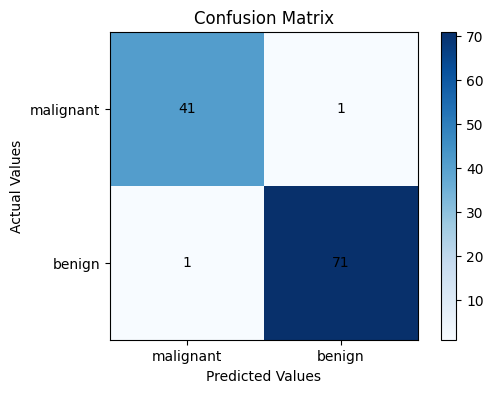

In [11]:
# Step 9: Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))

plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.xticks([0, 1], data.target_names)
plt.yticks([0, 1], data.target_names)

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

In [12]:
# Step 10: Classification Report

print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [13]:
# Step 11: ROC-AUC Score

y_probability = model.predict_proba(X_test_scaled)[:, 1]

auc = roc_auc_score(y_test, y_probability)

print("ROC-AUC Score:", auc)

ROC-AUC Score: 0.9953703703703703


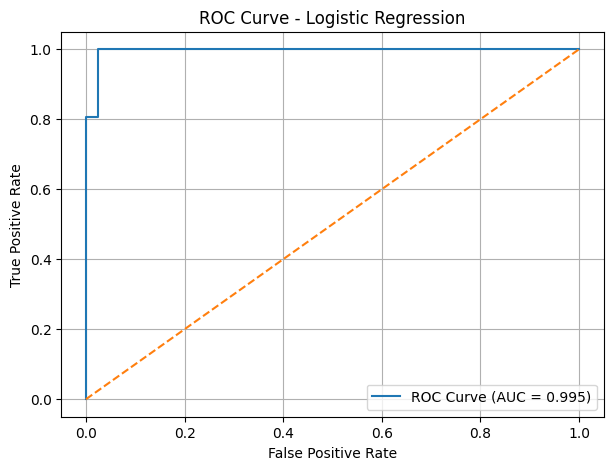

In [14]:
# Plot ROC Curve

fpr, tpr, thresholds = roc_curve(y_test, y_probability)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")

plt.legend()
plt.grid()
plt.show()

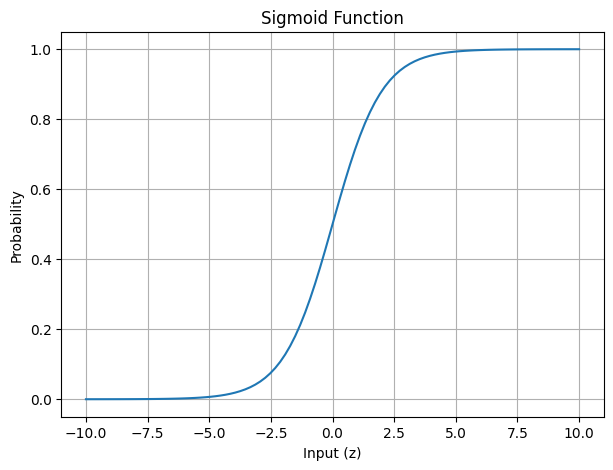

In [15]:
# Step 12: Sigmoid Function

z = np.linspace(-10, 10, 100)

sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(7, 5))

plt.plot(z, sigmoid)

plt.title("Sigmoid Function")
plt.xlabel("Input (z)")
plt.ylabel("Probability")

plt.grid()
plt.show()

In [16]:
# Step 13: Threshold Tuning

threshold = 0.4

y_pred_new = (y_probability >= threshold).astype(int)

print("New Threshold:", threshold)

print("\nNew Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_new))

print("\nNew Classification Report:")
print(classification_report(
    y_test,
    y_pred_new,
    target_names=data.target_names
))

New Threshold: 0.4

New Confusion Matrix:
[[41  1]
 [ 1 71]]

New Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [18]:
# Compare Thresholds

print("Threshold 0.5")
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))

print("\nThreshold 0.4")
print("Precision:", precision_score(y_test, y_pred_new))
print("Recall:", recall_score(y_test, y_pred_new))

Threshold 0.5
Precision: 0.9861111111111112
Recall: 0.9861111111111112

Threshold 0.4
Precision: 0.9861111111111112
Recall: 0.9861111111111112


In [19]:
# Save Dataset as CSV

dataset = X.copy()
dataset["target"] = y

dataset.to_csv("breast_cancer_dataset.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [20]:
from google.colab import files

files.download("breast_cancer_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>